<a href="https://colab.research.google.com/github/AlvinManoj05/Computer-Vision-/blob/main/CIFAR100_CNN_VGG16_Case_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AIML Computer Vision Case Study: CIFAR-100



## 1. Imports and reproducibility


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print('TensorFlow:', tf.__version__)
print('Available GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load and preprocess CIFAR-100

CIFAR-100 contains 50,000 training and 10,000 test color images, each 32×32, across 100 fine-grained classes. Pixel values are converted to floats in [0, 1]. We hold out 5,000 training images for validation; the test set is kept for final evaluation only. VGG-16 expects larger inputs, so a dataset pipeline resizes images to 96×96 and applies VGG's ImageNet preprocessing.

In [ ]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar100.load_data(label_mode='fine')
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
y_train = y_train.squeeze()
y_test = y_test.squeeze()

# Deterministic validation split: 45,000 train / 5,000 validation.
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(x_train))
val_idx, train_idx = indices[:5000], indices[5000:]
x_val, y_val = x_train[val_idx], y_train[val_idx]
x_train, y_train = x_train[train_idx], y_train[train_idx]

NUM_CLASSES = 100
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(images, labels, training=False, vgg=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(10000, seed=SEED, reshuffle_each_iteration=True)
    def prepare(image, label):
        if vgg:
            image = tf.image.resize(image, (96, 96))
            image = image * 255.0
            image = keras.applications.vgg16.preprocess_input(image)
        return image, tf.cast(label, tf.int32)
    return ds.map(prepare, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(x_train, y_train, training=True)
val_ds = make_ds(x_val, y_val)
test_ds = make_ds(x_test, y_test)
vgg_train_ds = make_ds(x_train, y_train, training=True, vgg=True)
vgg_val_ds = make_ds(x_val, y_val, vgg=True)
vgg_test_ds = make_ds(x_test, y_test, vgg=True)
print('Train:', x_train.shape, '| Validation:', x_val.shape, '| Test:', x_test.shape)

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 1505s 9us/step
Train: (45000, 32, 32, 3) | Validation: (5000, 32, 32, 3) | Test: (10000, 32, 32, 3)


## 3. Build the custom CNN


In [ ]:
def build_custom_cnn():
    inputs = keras.Input(shape=(32, 32, 3), name='image')
    x = inputs
    for filters, drop_rate in [(32, 0.20), (64, 0.30), (128, 0.40)]:
        x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal',
                         kernel_regularizer=keras.regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal',
                         kernel_regularizer=keras.regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(drop_rate)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu', kernel_initializer='he_normal',
                     kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.50)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='class_probabilities')(x)
    return keras.Model(inputs, outputs, name='custom_cnn')

custom_model = build_custom_cnn()
custom_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                     loss='sparse_categorical_crossentropy', metrics=['accuracy'])
custom_model.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 347,524 (1.33 MB)

 Trainable params: 346,628 (1.32 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
# Save the architecture diagram and the full model summary as submission artifacts.
keras.utils.plot_model(custom_model, to_file='custom_cnn_architecture.png',
                       show_shapes=True, show_layer_names=True, dpi=100)
with open('custom_cnn_summary.txt', 'w') as f:
    custom_model.summary(print_fn=lambda line: f.write(line + '\n'))

## 4. Train the custom CNN

EarlyStopping restores the best validation-loss weights. ModelCheckpoint keeps the best full model on disk, so it can be loaded later even if the runtime disconnects.

In [ ]:
EPOCHS_CUSTOM = 3
custom_callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint('best_custom_cnn.keras', monitor='val_loss',
                                    save_best_only=True, verbose=1)
]
history_custom = custom_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_CUSTOM,
                                  callbacks=custom_callbacks)

Epoch 1/3
704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.0504 - loss: 4.5165
Epoch 1: val_loss improved from None to 3.79065, saving model to best_custom_cnn.keras

Epoch 1: finished saving model to best_custom_cnn.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 42s 30ms/step - accuracy: 0.0728 - loss: 4.2248 - val_accuracy: 0.1244 - val_loss: 3.7907
Epoch 2/3
702/704 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1211 - loss: 3.7890
Epoch 2: val_loss improved from 3.79065 to 3.46173, saving model to best_custom_cnn.keras

Epoch 2: finished saving model to best_custom_cnn.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.1379 - loss: 3.6888 - val_accuracy: 0.1724 - val_loss: 3.4617
Epoch 3/3
698/704 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1933 - loss: 3.3989
Epoch 3: val_loss improved from 3.46173 to 3.32109, saving model to best_custom_cnn.keras

Epoch 3: finished saving model to best_custom_cnn.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.2002 - loss: 

## 5. Build and train VGG-16

In [ ]:
def build_vgg16():
    base = keras.applications.VGG16(include_top=False, weights='imagenet',
                                    input_shape=(96, 96, 3))
    base.trainable = False  # transfer learning: train the new head first
    inputs = keras.Input(shape=(96, 96, 3), name='image')
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='class_probabilities')(x)
    return keras.Model(inputs, outputs, name='vgg16_cifar100')

vgg_model = build_vgg16()
vgg_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
vgg_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "vgg16_cifar100"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,871,716 (56.73 MB)

 Trainable params: 157,028 (613.39 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
keras.utils.plot_model(vgg_model, to_file='vgg16_architecture.png',
                       show_shapes=True, show_layer_names=True, dpi=100)
with open('vgg16_summary.txt', 'w') as f:
    vgg_model.summary(print_fn=lambda line: f.write(line + '\n'))

In [ ]:
EPOCHS_VGG = 1
vgg_callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint('best_vgg16.keras', monitor='val_loss',
                                    save_best_only=True, verbose=1)
]
history_vgg = vgg_model.fit(vgg_train_ds, validation_data=vgg_val_ds, epochs=EPOCHS_VGG,
                            callbacks=vgg_callbacks)

704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.1835 - loss: 4.6167
Epoch 1: val_loss improved from None to 1.97756, saving model to best_vgg16.keras

Epoch 1: finished saving model to best_vgg16.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 59s 76ms/step - accuracy: 0.2812 - loss: 3.2648 - val_accuracy: 0.4776 - val_loss: 1.9776
Restoring model weights from the end of the best epoch: 1.


## 6. Evaluate both models on the test set

In [ ]:
custom_test_loss, custom_test_acc = custom_model.evaluate(test_ds, verbose=1)
vgg_test_loss, vgg_test_acc = vgg_model.evaluate(vgg_test_ds, verbose=1)

comparison = pd.DataFrame({
    'Model': ['Custom CNN', 'VGG-16 (ImageNet transfer learning)'],
    'Test loss': [custom_test_loss, vgg_test_loss],
    'Test accuracy (%)': [100 * custom_test_acc, 100 * vgg_test_acc]
})
display(comparison.style.format({'Test loss': '{:.4f}', 'Test accuracy (%)': '{:.2f}%'}))
comparison.to_csv('test_accuracy_comparison.csv', index=False)

157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.2138 - loss: 3.3080
157/157 ━━━━━━━━━━━━━━━━━━━━ 12s 73ms/step - accuracy: 0.4703 - loss: 1.9906


,Model,Test loss,Test accuracy (%)
0,Custom CNN,3.3080,21.38%
1,VGG-16 (ImageNet transfer learning),1.9906,47.03%


## 7. Plot training and validation curves


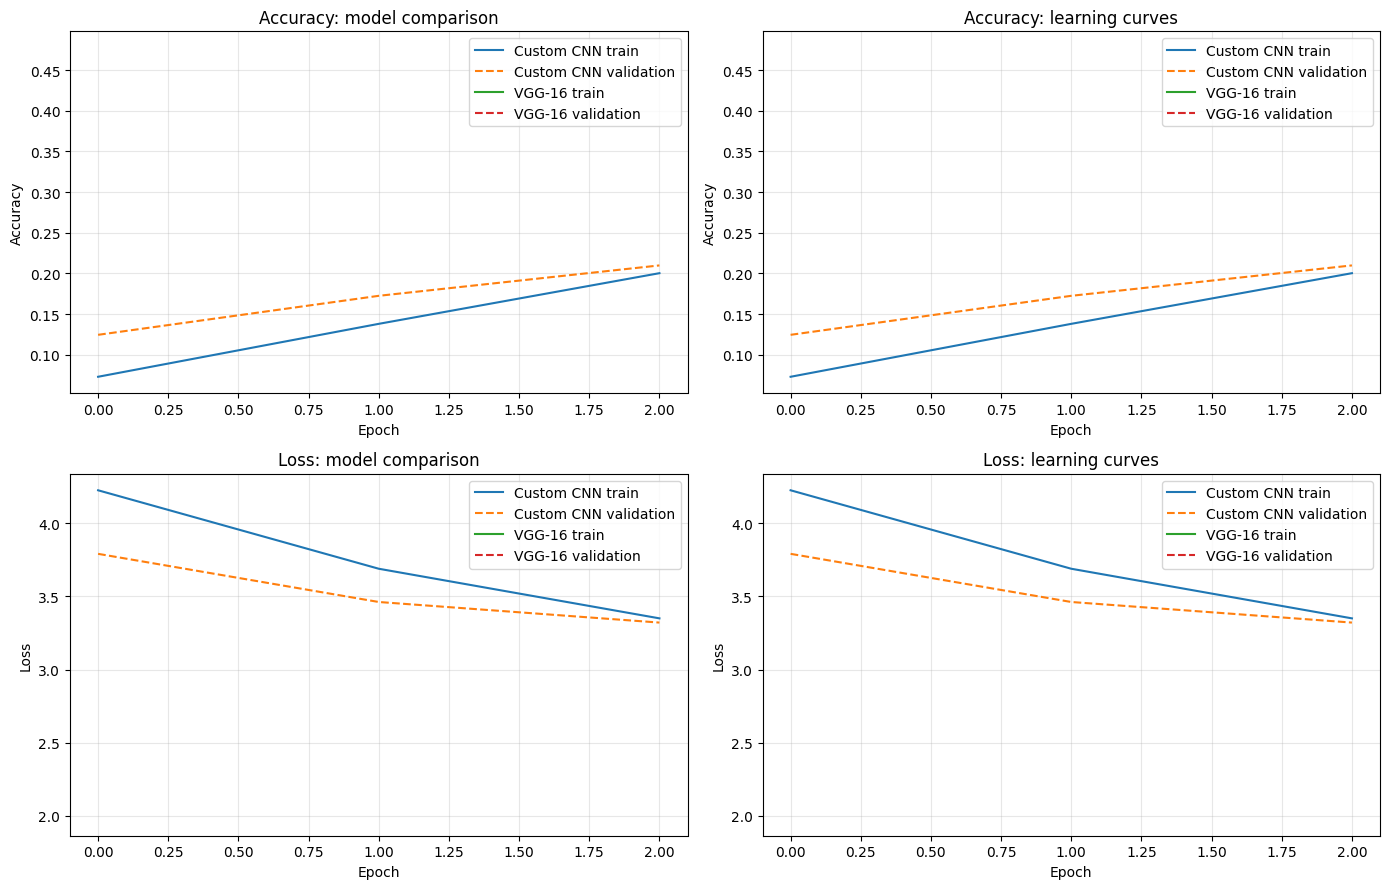

In [ ]:
def plot_histories(histories):
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    metrics = [('accuracy', 'Accuracy'), ('loss', 'Loss')]
    for row, (metric, label) in enumerate(metrics):
        for history, name in histories:
            axes[row, 0].plot(history.history[metric], label=f'{name} train')
            axes[row, 0].plot(history.history['val_' + metric], linestyle='--', label=f'{name} validation')
        axes[row, 0].set_title(f'{label}: model comparison')
        axes[row, 0].set_xlabel('Epoch'); axes[row, 0].set_ylabel(label); axes[row, 0].legend(); axes[row, 0].grid(True, alpha=.3)
        for history, name in histories:
            axes[row, 1].plot(history.history[metric], label=f'{name} train')
            axes[row, 1].plot(history.history['val_' + metric], linestyle='--', label=f'{name} validation')
        axes[row, 1].set_title(f'{label}: learning curves')
        axes[row, 1].set_xlabel('Epoch'); axes[row, 1].set_ylabel(label); axes[row, 1].legend(); axes[row, 1].grid(True, alpha=.3)
    plt.tight_layout()
    plt.savefig('training_validation_curves.png', dpi=160, bbox_inches='tight')
    plt.show()

plot_histories([(history_custom, 'Custom CNN'), (history_vgg, 'VGG-16')])

## 8. View architecture diagrams


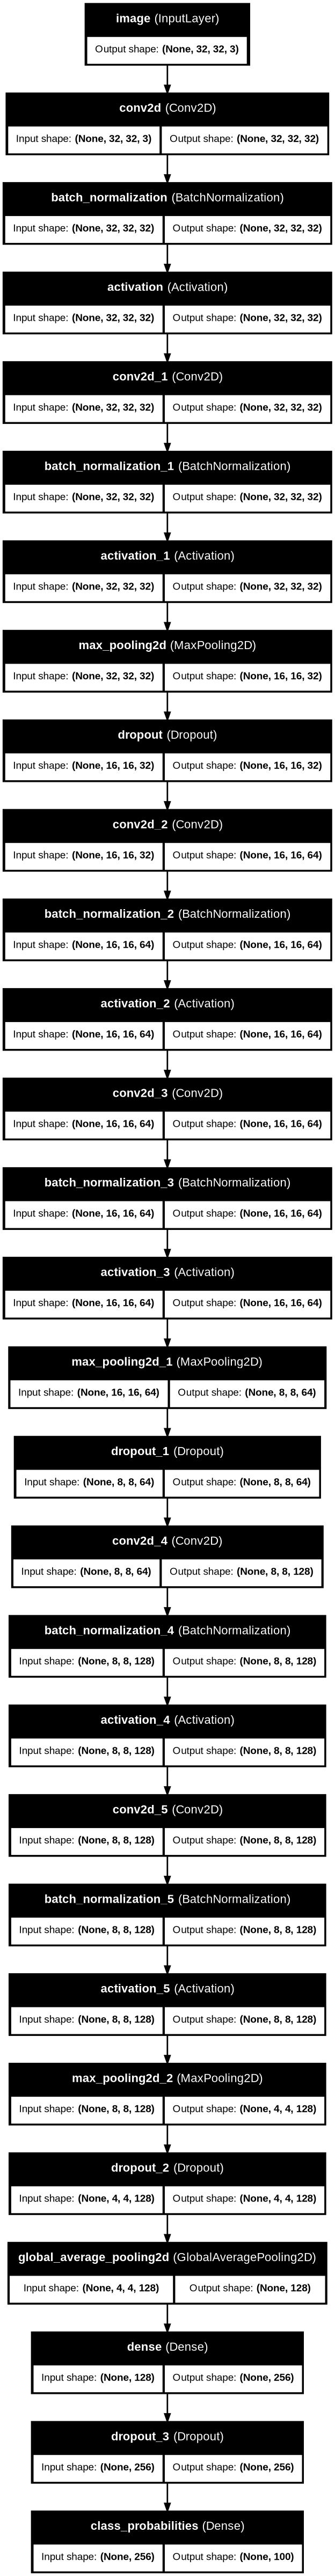

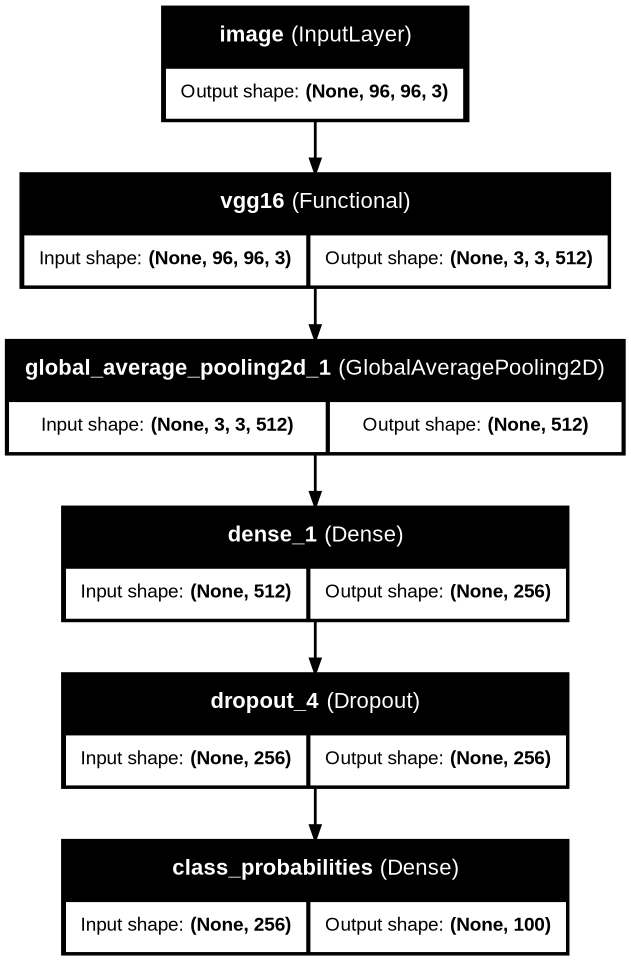

In [ ]:
from IPython.display import Image, display
display(Image('custom_cnn_architecture.png'))
display(Image('vgg16_architecture.png'))